In [30]:
import os
import numpy as np
from PIL import Image
from torch.utils.data import Dataset


class RESIDEDataset(Dataset):

    def __init__(self, root, transform=None):

        self.root = root
        self.transform = transform

        self.hazy_dir = os.path.join(root, "hazy")
        self.clean_dir = os.path.join(root, "GT")

        # Get hazy image filenames
        self.files = sorted(os.listdir(self.clean_dir))

        # # Keep only images that exist in both folders
        # self.hazy_files = [
        #     f for f in self.hazy_files
        #     if os.path.exists(
        #         os.path.join(self.clean_dir, f)
        #     )
        # ]

        print("Total paired images:", len(self.files))

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):

        filename = self.files[idx]

        hazy_path = os.path.join(
            self.hazy_dir,
            filename
        )

        clean_path = os.path.join(
            self.clean_dir,
            filename
        )

        hazy = np.array(
            Image.open(hazy_path).convert("RGB")
        ).astype(np.float32) / 255.0

        clean = np.array(
            Image.open(clean_path).convert("RGB")
        ).astype(np.float32) / 255.0

        if self.transform:
            hazy, clean = self.transform(hazy, clean)

        # HWC → CHW
       
        hazy = torch.tensor(
            hazy.transpose(2, 0, 1),
            dtype=torch.float32
        )

        clean = torch.tensor(
            clean.transpose(2, 0, 1),
            dtype=torch.float32
        )

        return hazy, clean

In [31]:
root = f"/kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/train"
test_path = f"/kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/test"  #GT,hazy

dataset = RESIDEDataset(root)

print("Number of image pairs:", len(dataset))

Total paired images: 6000
Number of image pairs: 6000


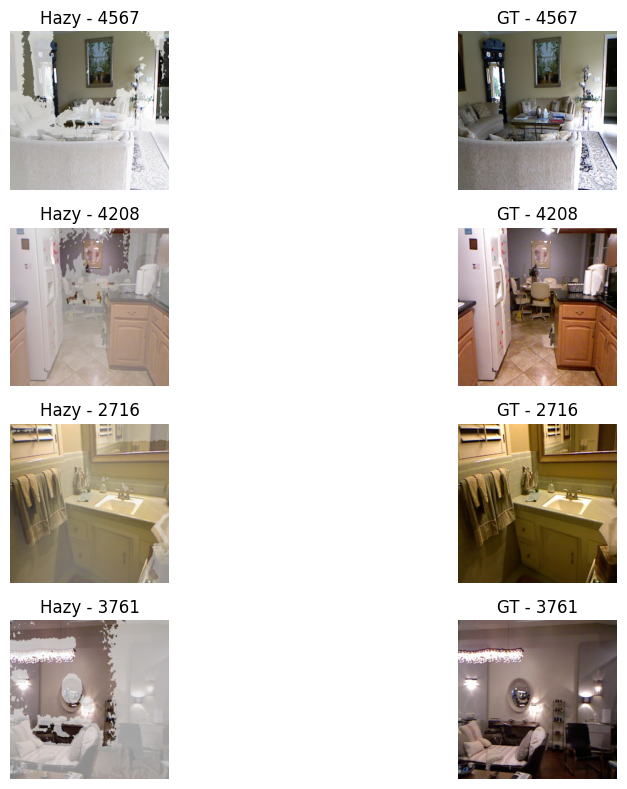

In [32]:
import random
import matplotlib.pyplot as plt

indices = random.sample(range(len(dataset)), 4)

plt.figure(figsize=(12, 8))

for i, idx in enumerate(indices):

    hazy, clean = dataset[idx]

    hazy_img = hazy.permute(1, 2, 0).numpy()
    clean_img = clean.permute(1, 2, 0).numpy()

    plt.subplot(4, 2, 2*i + 1)
    plt.imshow(hazy_img)
    plt.title(f"Hazy - {idx}")
    plt.axis("off")

    plt.subplot(4, 2, 2*i + 2)
    plt.imshow(clean_img)
    plt.title(f"GT - {idx}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# 1. Lightweight CNN Stem
# ============================================================

class Stem(nn.Module):

    def __init__(self, in_channels=3, features=32):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                features,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# ============================================================
# 2. Spatially Adaptive Multi-Scale Block
# ============================================================

class SpatialAdaptiveMultiScaleBlock(nn.Module):

    def __init__(self, channels=32):
        super().__init__()

        # Local scale
        self.branch_3x3 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1,
            groups=channels
        )

        # Medium scale
        self.branch_5x5 = nn.Conv2d(
            channels,
            channels,
            kernel_size=5,
            padding=2,
            groups=channels
        )

        # Large receptive field
        self.branch_dilated = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=2,
            dilation=2,
            groups=channels
        )

        # Spatial scale gating
        self.gate = nn.Sequential(
            nn.Conv2d(
                channels * 3,
                channels,
                kernel_size=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                channels,
                3,
                kernel_size=1
            )
        )

        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):

        f1 = self.branch_3x3(x)
        f2 = self.branch_5x5(x)
        f3 = self.branch_dilated(x)

        combined = torch.cat(
            [f1, f2, f3],
            dim=1
        )

        weights = self.gate(combined)
8
        weights = self.softmax(weights)

        w1 = weights[:, 0:1, :, :]
        w2 = weights[:, 1:2, :, :]
        w3 = weights[:, 2:3, :, :]

        out = (
            w1 * f1 +
            w2 * f2 +
            w3 * f3
        )

        return out


# ============================================================
# 3. Channel Attention
# ============================================================

class ChannelAttention(nn.Module):

    def __init__(self, channels=32, reduction=8):
        super().__init__()

        hidden = channels // reduction

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(
                channels,
                hidden,
                kernel_size=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                hidden,
                channels,
                kernel_size=1
            ),
            nn.Sigmoid()
        )

    def forward(self, x):

        pooled = self.pool(x)

        weights = self.fc(pooled)

        return x * weights


# ============================================================
# 4. Spatial Attention
# ============================================================

class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):
        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size=kernel_size,
            padding=kernel_size // 2
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_map = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_map, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        combined = torch.cat(
            [avg_map, max_map],
            dim=1
        )

        attention = self.sigmoid(
            self.conv(combined)
        )

        return x * attention


# ============================================================
# 5. Residual Refinement
# ============================================================

class ResidualRefinement(nn.Module):

    def __init__(self, channels=32):
        super().__init__()

        self.refine = nn.Sequential(

            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1
            )
        )

    def forward(self, x):

        residual = self.refine(x)

        return x + residual


# ============================================================
# 6. Combined Feature Block
# ============================================================

class FeatureBlock(nn.Module):

    def __init__(self, channels):
        super().__init__()

        self.multi_scale = SpatialAdaptiveMultiScaleBlock(
            channels
        )

        self.channel_attention = ChannelAttention(
            channels
        )

        self.spatial_attention = SpatialAttention()

        self.refinement = ResidualRefinement(
            channels
        )

    def forward(self, x):

        x = self.multi_scale(x)

        x = self.channel_attention(x)

        x = self.spatial_attention(x)

        x = self.refinement(x)

        return x


# ============================================================
# 7. Downsampling Block
# ============================================================

class DownsampleBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                stride=2,
                padding=1
            ),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        return self.block(x)


# ============================================================
# 8. Upsampling Block
# ============================================================

class UpsampleBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        x = F.interpolate(
            x,
            scale_factor=2,
            mode="bilinear",
            align_corners=False
        )

        return self.conv(x)


# ============================================================
# 9. Lightweight U-Net
# ============================================================

class LightweightUNet(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.down1 = DownsampleBlock(32, 64)

        self.encoder1 = FeatureBlock(64)

        self.down2 = DownsampleBlock(64, 96)

        self.encoder2 = FeatureBlock(96)

        # Bottleneck
        self.bottleneck = FeatureBlock(96)

        # Decoder
        self.up1 = UpsampleBlock(96, 64)

        self.decoder1 = nn.Sequential(

            nn.Conv2d(
                64 + 64,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True)
        )

        self.up2 = UpsampleBlock(64, 32)

        self.decoder2 = nn.Sequential(

            nn.Conv2d(
                32 + 32,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        # 256x256
        skip1 = x

        # 256 -> 128
        x = self.down1(x)

        skip2 = self.encoder1(x)

        # 128 -> 64
        x = self.down2(skip2)

        x = self.encoder2(x)

        # Bottleneck
        x = self.bottleneck(x)

        # 64 -> 128
        x = self.up1(x)

        x = torch.cat(
            [x, skip2],
            dim=1
        )

        x = self.decoder1(x)

        # 128 -> 256
        x = self.up2(x)

        x = torch.cat(
            [x, skip1],
            dim=1
        )

        x = self.decoder2(x)

        return x


# ============================================================
# 10. Reconstruction Head
# ============================================================

class ReconstructionHead(nn.Module):

    def __init__(self, in_channels=32):
        super().__init__()

        self.head = nn.Conv2d(
            in_channels,
            3,
            kernel_size=3,
            padding=1
        )

    def forward(self, x):
        return self.head(x)


# ============================================================
# 11. Complete Dehazing Network
# ============================================================
class DehazingNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.stem = Stem(
            in_channels=3,
            features=32
        )

        self.feature_block = FeatureBlock(32)

        self.unet = LightweightUNet()

        self.reconstruction = ReconstructionHead(32)

    def forward(self, x):

        # Keep original hazy image
        identity = x

        x = self.stem(x)

        x = self.feature_block(x)

        x = self.unet(x)

        # Predict residual correction
        residual = self.reconstruction(x)

        # Hazy + learned correction
        output = identity + residual

        # Keep output in valid image range
        output = torch.clamp(output, 0, 1)

        return output

In [35]:
hazy, clean = dataset[0]

hazy_tensor = (
    hazy
    .unsqueeze(0)
    .float()
    .to(device)
)

clean_tensor = (
    clean
    .unsqueeze(0)
    .float()
    .to(device)
)

with torch.no_grad():
    output = model(hazy_tensor)

print("Input :", hazy_tensor.shape)
print("Output:", output.shape)
print(
    "Output range:",
    output.min().item(),
    output.max().item()
)

Input : torch.Size([1, 3, 400, 400])
Output: torch.Size([1, 3, 400, 400])
Output range: 0.0 1.0


In [37]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 757,919
Trainable parameters: 757,919


In [39]:
print("device variable:", device)
print("model device:", next(model.parameters()).device)

hazy, clean = dataset[0]

print("dataset hazy:", type(hazy), hazy.device)

hazy_tensor = hazy.unsqueeze(0).float().to(device)

print("input device:", hazy_tensor.device)

with torch.no_grad():
    output = model(hazy_tensor)

print("Input :", hazy_tensor.shape)
print("Output:", output.shape)

device variable: cuda
model device: cuda:0
dataset hazy: <class 'torch.Tensor'> cpu
input device: cuda:0
Input : torch.Size([1, 3, 400, 400])
Output: torch.Size([1, 3, 400, 400])


In [40]:
import matplotlib.pyplot as plt

input_img = (
    hazy_tensor
    .squeeze(0)
    .permute(1, 2, 0)
    .numpy()
)

output_img = (
    output
    .squeeze(0)
    .permute(1, 2, 0)
    .numpy()
)

clean_img = (
    clean
    .permute(1, 2, 0)
    .numpy()
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(input_img)
plt.title("Hazy Input")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(output_img)
plt.title("Untrained Output")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clean_img)
plt.title("Ground Truth")
plt.axis("off")

plt.tight_layout()
plt.show()

TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

In [ ]:
# !pip install pytorch_msssim

In [ ]:

class L1Loss(nn.Module):

    def __init__(self):
        super().__init__()
        self.loss = nn.L1Loss()

    def forward(self, pred, target):
        return self.loss(pred, target)
from pytorch_msssim import ssim


def ssim_loss(pred, target):

    return 1 - ssim(
        pred,
        target,
        data_range=1.0,
        size_average=True
    )

class EdgeLoss(nn.Module):

    def __init__(self):
        super().__init__()

        sobel_x = torch.tensor([
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]
        ], dtype=torch.float32)

        sobel_y = torch.tensor([
            [-1, -2, -1],
            [ 0,  0,  0],
            [ 1,  2,  1]
        ], dtype=torch.float32)

        self.register_buffer(
            "sobel_x",
            sobel_x.view(1, 1, 3, 3)
        )

        self.register_buffer(
            "sobel_y",
            sobel_y.view(1, 1, 3, 3)
        )

    def forward(self, pred, target):

        # Apply Sobel independently to RGB channels
        sobel_x = self.sobel_x.repeat(3, 1, 1, 1)
        sobel_y = self.sobel_y.repeat(3, 1, 1, 1)

        pred_x = F.conv2d(
            pred,
            sobel_x,
            padding=1,
            groups=3
        )

        pred_y = F.conv2d(
            pred,
            sobel_y,
            padding=1,
            groups=3
        )

        target_x = F.conv2d(
            target,
            sobel_x,
            padding=1,
            groups=3
        )

        target_y = F.conv2d(
            target,
            sobel_y,
            padding=1,
            groups=3
        )

        loss_x = F.l1_loss(pred_x, target_x)
        loss_y = F.l1_loss(pred_y, target_y)

        return loss_x + loss_y
class ColorLoss(nn.Module):

    def __init__(self):
        super().__init__()

    def forward(self, pred, target):

        pred_mean = pred.mean(
            dim=(2, 3),
            keepdim=True
        )

        target_mean = target.mean(
            dim=(2, 3),
            keepdim=True
        )

        return F.l1_loss(
            pred_mean,
            target_mean
        )
class DehazingLoss(nn.Module):

    def __init__(
        self,
        lambda_rec=1.0,
        lambda_ssim=0.5,
        lambda_edge=0.1,
        lambda_color=0.05
    ):
        super().__init__()

        self.lambda_rec = lambda_rec
        self.lambda_ssim = lambda_ssim
        self.lambda_edge = lambda_edge
        self.lambda_color = lambda_color

        self.edge_loss = EdgeLoss()
        self.color_loss = ColorLoss()

    def forward(self, pred, target):

        # Reconstruction
        rec = F.l1_loss(
            pred,
            target
        )

        # Structural similarity
        ssim_l = ssim_loss(
            pred,
            target
        )

        # Edge preservation
        edge = self.edge_loss(
            pred,
            target
        )

        # Color preservation
        color = self.color_loss(
            pred,
            target
        )

        total = (
            self.lambda_rec * rec
            + self.lambda_ssim * ssim_l
            + self.lambda_edge * edge
            + self.lambda_color * color
        )

        return total, {
            "reconstruction": rec.item(),
            "ssim": ssim_l.item(),
            "edge": edge.item(),
            "color": color.item()
        }
    

In [ ]:
import torch

hazy, clean = dataset[0]

hazy = hazy.unsqueeze(0).float()
clean = clean.unsqueeze(0).float()

print("Hazy :", hazy.shape)
print("Clean:", clean.shape)

with torch.no_grad():
    output = model(hazy)

print("Output:", output.shape)
print(
    "Output range:",
    output.min().item(),
    output.max().item()
)

In [ ]:
from torch.utils.data import DataLoader

train_dataset = RESIDEDataset(
    "/kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/train"
)

val_dataset = RESIDEDataset(
    "/kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/test"
)
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

model = DehazingNet().to(device)
criterion = DehazingLoss().to(device)

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)

In [ ]:
from tqdm.auto import tqdm
import numpy as np
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

num_epochs = 10
best_ssim = -1.0

save_path = "/kaggle/working/best_dehazing_model.pth"

for epoch in range(num_epochs):

    print(f"\n========== Epoch {epoch + 1}/{num_epochs} ==========")

    # =====================================================
    # TRAIN
    # =====================================================

    model.train()
    running_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc="Training",
        leave=True
    )

    for batch_idx, (hazy, clean) in enumerate(train_bar):

        hazy = hazy.to(device, non_blocking=True)
        clean = clean.to(device, non_blocking=True)

        optimizer.zero_grad()

        pred = model(hazy)

        loss, loss_components = criterion(
            pred,
            clean
        )

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = running_loss / len(train_loader)

    # =====================================================
    # VALIDATION
    # =====================================================

    model.eval()

    val_psnr_list = []
    val_ssim_list = []

    val_bar = tqdm(
        val_loader,
        desc="Validation",
        leave=True
    )

    with torch.no_grad():

        for hazy, clean in val_bar:

            hazy = hazy.to(device, non_blocking=True)
            clean = clean.to(device, non_blocking=True)

            pred = model(hazy)
            pred = pred.clamp(0, 1)

            pred_np = (
                pred
                .permute(0, 2, 3, 1)
                .cpu()
                .numpy()
            )

            clean_np = (
                clean
                .permute(0, 2, 3, 1)
                .cpu()
                .numpy()
            )

            for p, c in zip(pred_np, clean_np):

                val_psnr_list.append(
                    peak_signal_noise_ratio(
                        c,
                        p,
                        data_range=1.0
                    )
                )

                val_ssim_list.append(
                    structural_similarity(
                        c,
                        p,
                        data_range=1.0,
                        channel_axis=2
                    )
                )

    val_psnr = np.mean(val_psnr_list)
    val_ssim = np.mean(val_ssim_list)

    scheduler.step()

    current_lr = scheduler.get_last_lr()[0]

    print(f"\nTrain Loss : {train_loss:.4f}")
    print(f"Val PSNR   : {val_psnr:.2f} dB")
    print(f"Val SSIM   : {val_ssim:.4f}")
    print(f"LR         : {current_lr:.2e}")

    # =====================================================
    # SAVE BEST
    # =====================================================

    if val_ssim > best_ssim:

        best_ssim = val_ssim

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "val_ssim": val_ssim,
            "val_psnr": val_psnr,
            "train_loss": train_loss
        }, save_path)

        print(
            f"✅ Best model saved | "
            f"SSIM: {val_ssim:.4f}"
        )